# Phishing Website Detection: Machine Learning Report

This notebook documents the complete project pipeline. The dataset uses `Result = -1` for phishing and `Result = 1` for legitimate websites. For the requested regression workflow, the target is created as a numeric phishing score: `1` for phishing and `0` for legitimate websites. Predictions are converted back to classes with a 0.5 threshold.


## 1. Import libraries


In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split

SEED = 42
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "dataset.csv").exists():
    PROJECT_ROOT = Path("Phishing_detection")
DATA_PATH = PROJECT_ROOT / "data" / "dataset.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "phishing_random_forest_regressor.joblib"


c:\Users\Kumar\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 2. Load the dataset


In [2]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Dataset: {DATA_PATH}")
print(f"Rows: {raw_df.shape[0]:,} | Columns: {raw_df.shape[1]:,}")
display(raw_df.head())


Dataset: d:\SEM-5\ML CS Lab\Project\Final_Project\data\dataset.csv
Rows: 11,055 | Columns: 32


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


## 3. Understand the data

The `index` field is an identifier, the remaining input columns are encoded website features, and `Result` is the original class label.


In [3]:
display(raw_df.dtypes.rename("dtype").to_frame())
display(raw_df.describe(include="all").T.head(10))
print("Original class counts (-1=phishing, 1=legitimate):")
display(raw_df["Result"].value_counts().sort_index())
print(f"Duplicate rows: {raw_df.duplicated().sum():,}")


,dtype
index,int64
having_IPhaving_IP_Address,int64
URLURL_Length,int64
Shortining_Service,int64
having_At_Symbol,int64
double_slash_redirecting,int64
Prefix_Suffix,int64
having_Sub_Domain,int64
SSLfinal_State,int64
Domain_registeration_length,int64


,count,mean,std,min,25%,50%,75%,max
index,11055.0,5528.000000,3191.447947,1.0,2764.5,5528.0,8291.5,11055.0
having_IPhaving_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URLURL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0


Original class counts (-1=phishing, 1=legitimate):


Result
-1    4898
 1    6157
Name: count, dtype: int64

Duplicate rows: 0


## 4. Handling missing values (imputation)

Missing values are imputed with the median calculated from the training data. This avoids using information from the test set during preprocessing.


In [4]:
missing = raw_df.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].rename("missing_values").to_frame())
print("No missing values detected." if not missing.any() else "Missing values will be imputed below.")


,missing_values


No missing values detected.


## 5. Data preprocessing & target creation


In [5]:
df = raw_df.drop_duplicates().reset_index(drop=True).copy()
feature_columns = [c for c in df.columns if c not in {"index", "Result"}]
X = df[feature_columns].apply(pd.to_numeric, errors="coerce")
y = (df["Result"] == -1).astype(float)
print(f"Rows after duplicate removal: {len(df):,}")
print(f"Candidate features: {len(feature_columns)}")
print(f"Target counts (1=phishing, 0=legitimate): {y.value_counts().to_dict()}")


Rows after duplicate removal: 11,055
Candidate features: 30
Target counts (1=phishing, 0=legitimate): {0.0: 6157, 1.0: 4898}


## 6. Feature selection

The identifier and original target are excluded. A quick absolute-correlation ranking is used to retain the top 20 predictive features. The selection is performed on the training partition only after the split, preventing test-set leakage.


## 7. Train–test split


In [6]:
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train_all), columns=feature_columns, index=X_train_all.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test_all), columns=feature_columns, index=X_test_all.index)
correlations = X_train_imputed.assign(target=y_train).corr(numeric_only=True)["target"].drop("target").abs()
selected_features = correlations.nlargest(min(20, len(correlations))).index.tolist()
X_train = X_train_imputed[selected_features]
X_test = X_test_imputed[selected_features]
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Selected features ({len(selected_features)}): {selected_features}")


Training rows: 8,844 | Test rows: 2,211
Selected features (20): ['SSLfinal_State', 'URL_of_Anchor', 'web_traffic', 'Prefix_Suffix', 'having_Sub_Domain', 'Request_URL', 'Links_in_tags', 'Domain_registeration_length', 'SFH', 'Google_Index', 'age_of_domain', 'Page_Rank', 'having_IPhaving_IP_Address', 'Statistical_report', 'DNSRecord', 'Shortining_Service', 'Abnormal_URL', 'URLURL_Length', 'having_At_Symbol', 'double_slash_redirecting']


## 8. Model building – Random Forest Regressor


In [7]:
model = RandomForestRegressor(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
    min_samples_leaf=2,
)
model.fit(X_train, y_train)
print("Random Forest Regressor trained successfully.")


Random Forest Regressor trained successfully.


## 9. Prediction


In [8]:
y_pred_score = np.clip(model.predict(X_test), 0, 1)
y_pred = (y_pred_score >= 0.5).astype(int)
display(pd.DataFrame({"actual": y_test.astype(int), "predicted_score": y_pred_score, "predicted_class": y_pred}).head())


,actual,predicted_score,predicted_class
3588,1,1.0,1
1688,1,1.0,1
7280,1,1.0,1
2551,1,1.0,1
235,0,0.0,0


## 10. Model evaluation


In [9]:
metrics = {
    "mae": mean_absolute_error(y_test, y_pred_score),
    "rmse": mean_squared_error(y_test, y_pred_score) ** 0.5,
    "r2": r2_score(y_test, y_pred_score),
    "classification_accuracy": accuracy_score(y_test, y_pred),
}
print({name: round(value, 4) for name, value in metrics.items()})
print(classification_report(y_test, y_pred, target_names=["legitimate", "phishing"]))
print("Confusion matrix [legitimate, phishing]:")
display(pd.DataFrame(confusion_matrix(y_test, y_pred), index=["actual_0", "actual_1"], columns=["predicted_0", "predicted_1"]))


{'mae': 0.0595, 'rmse': 0.1664, 'r2': 0.8879, 'classification_accuracy': 0.9679}
              precision    recall  f1-score   support

  legitimate       0.97      0.98      0.97      1231
    phishing       0.97      0.96      0.96       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211

Confusion matrix [legitimate, phishing]:


,predicted_0,predicted_1
actual_0,1203,28
actual_1,43,937


## 11. Feature importance


,importance
SSLfinal_State,0.642304
URL_of_Anchor,0.120513
Links_in_tags,0.035044
having_Sub_Domain,0.034237
web_traffic,0.031657
Prefix_Suffix,0.023616
age_of_domain,0.014841
Request_URL,0.013074
Domain_registeration_length,0.011775
having_IPhaving_IP_Address,0.010651


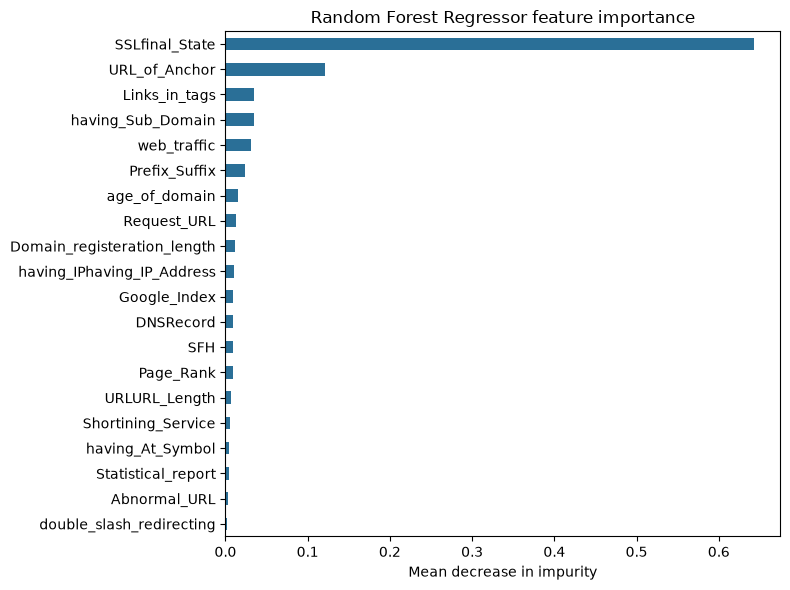

In [10]:
importance = pd.Series(model.feature_importances_, index=selected_features).sort_values(ascending=True)
display(importance.sort_values(ascending=False).to_frame("importance"))
importance.plot.barh(figsize=(8, 6), color="#2a6f97", title="Random Forest Regressor feature importance")
plt.xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()


## 12. Saving the model (Serialization)


In [11]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
artifact = {
    "model": model,
    "imputer": imputer,
    "all_features": feature_columns,
    "features": selected_features,
    "threshold": 0.5,
    "target_definition": "1=phishing, 0=legitimate",
}
joblib.dump(artifact, MODEL_PATH, compress=3)
print(f"Saved serialized model to {MODEL_PATH}")


Saved serialized model to d:\SEM-5\ML CS Lab\Project\Final_Project\models\phishing_random_forest_regressor.joblib


## 13. Loading the model & predicting on new data (Reusability)


In [12]:
loaded = joblib.load(MODEL_PATH)
new_data = raw_df.drop(columns=["index", "Result"], errors="ignore").iloc[[0]].copy()
new_data = new_data.reindex(columns=loaded["all_features"], fill_value=np.nan)
new_imputed = loaded["imputer"].transform(new_data)
new_imputed = pd.DataFrame(new_imputed, columns=loaded["all_features"])[loaded["features"]]
new_score = float(np.clip(loaded["model"].predict(new_imputed)[0], 0, 1))
new_class = "phishing" if new_score >= loaded["threshold"] else "legitimate"
print({"phishing_score": round(new_score, 4), "prediction": new_class})


{'phishing_score': 1.0, 'prediction': 'phishing'}


## 14. Conclusion

The pipeline loads and profiles the phishing dataset, removes duplicate records, imputes missing values using training-only statistics, creates a binary phishing target, selects the strongest features, trains a Random Forest Regressor, evaluates both regression and thresholded classification performance, and serializes the complete preprocessing/model artifact. Reloading the artifact allows the same preprocessing and prediction logic to be reused for new records without retraining.
